In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import dask
from dask.diagnostics import ProgressBar

import warnings
warnings.filterwarnings('ignore')

import geopandas as gpd
import regionmask
import xgcm
import regionate
import matplotlib.pyplot as plt
from shapely.geometry import box

import cmocean.cm as cm

import pandas as pd

In [14]:
nwa_data = "/dfs9/hfdrake_hpc/datasets/NWA/NWA12_COBALT_2025_04_bugfixes/gfdl.ncrc6-intel23-prod-hdf5/pp/"
data = "/pub/mariant3/bgcDrought/data/"

vars = {
    "thetao": (f"{nwa_data}ocean_monthly_z/ts/monthly/5yr/*.thetao.nc",     True),
    "no3":    (f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.no3.nc",    True),
    "o2":     (f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.o2.nc",     True),
    "chl":    (f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.chl.nc",    True),
    "dissoc": (f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.dissoc.nc", True),
    "dissic": (f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.dissic.nc", True),
}

In [17]:
provinces = {var: xr.open_dataset(f"{data}{var}_province_timeseries_1993-2022.nc")
            for var in vars}

provinces["thetao"]

<xarray.Dataset>
Dimensions:  (time: 360, region: 13)
Coordinates:
  * time     (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
    abbrevs  (region) object ...
    names    (region) object ...
  * region   (region) object 'ARCT' 'BPLR' 'CAMR' ... 'NWCS' 'PNEC' 'WTRA'
    month    (time) int64 ...
Data variables:
    obs      (region, time) float32 ...
    clim     (region, time) float32 ...
    per10    (region, time) float64 ...
    per90    (region, time) float64 ...

In [19]:
all_regions = provinces["thetao"].region.values

regions = [str(r) for r in all_regions
           if any(provinces[var].obs.sel(region=r).notnull().any() for var in vars)]

In [41]:
def plot_province(province):
    fig, axs = plt.subplots(len(vars), 1, figsize=(20, 3 * len(vars)), sharex=True)

    for ax, var in zip(axs, vars):
        p = provinces[var].sel(region=province)
        t = p.time.values

        ax.plot(t, p.obs,   "k",  lw=1, label="observed")
        ax.plot(t, p.clim,  color="grey", lw=1, label="climatology")
        ax.plot(t, p.per90, "r--", lw=1, label="90th percentile")
        ax.plot(t, p.per10, "--", color="darkorange", lw=1, label="10th percentile")

        ax.fill_between(t, p.per90, p.obs, where=p.obs > p.per90, interpolate=True, color="r", alpha=0.4)
        ax.fill_between(t, p.per10, p.obs, where=p.obs < p.per10, interpolate=True, color="orange", alpha=0.4)

        event = (p.obs > p.per90) | (p.obs < p.per10)
        ylim_data = ax.get_ylim()
        ax.fill_between(t, 0, 1, where=event, step="mid", color="lightgrey", alpha=0.6,
                        transform=ax.get_xaxis_transform(), zorder=0)
        ax.set_ylim(ylim_data)

        ax.set_ylabel(var)

    axs[0].legend(loc="upper left", fontsize=8, ncol=4)
    fig.suptitle(str(province))
    fig.tight_layout()
    fig.savefig(f"{data}../figures/exp/{province}_exploratory_ts.png", dpi=350, bbox_inches="tight")
    plt.show()

# plot_province(regions[0])

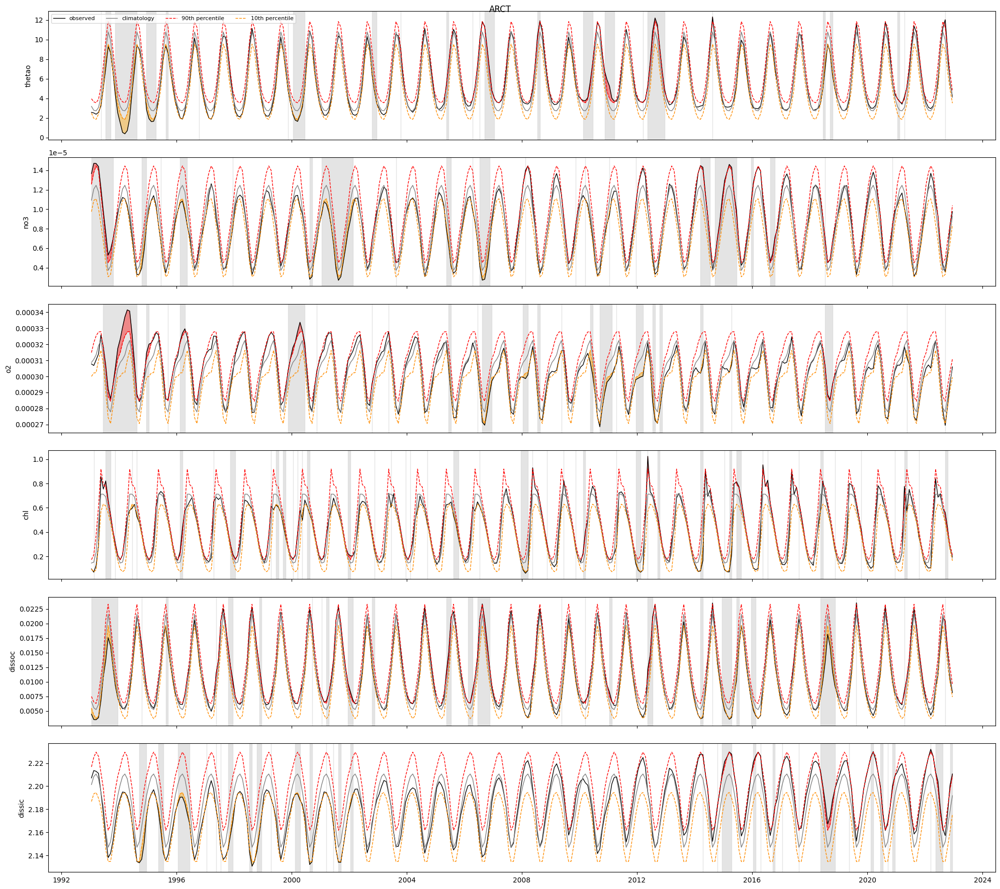

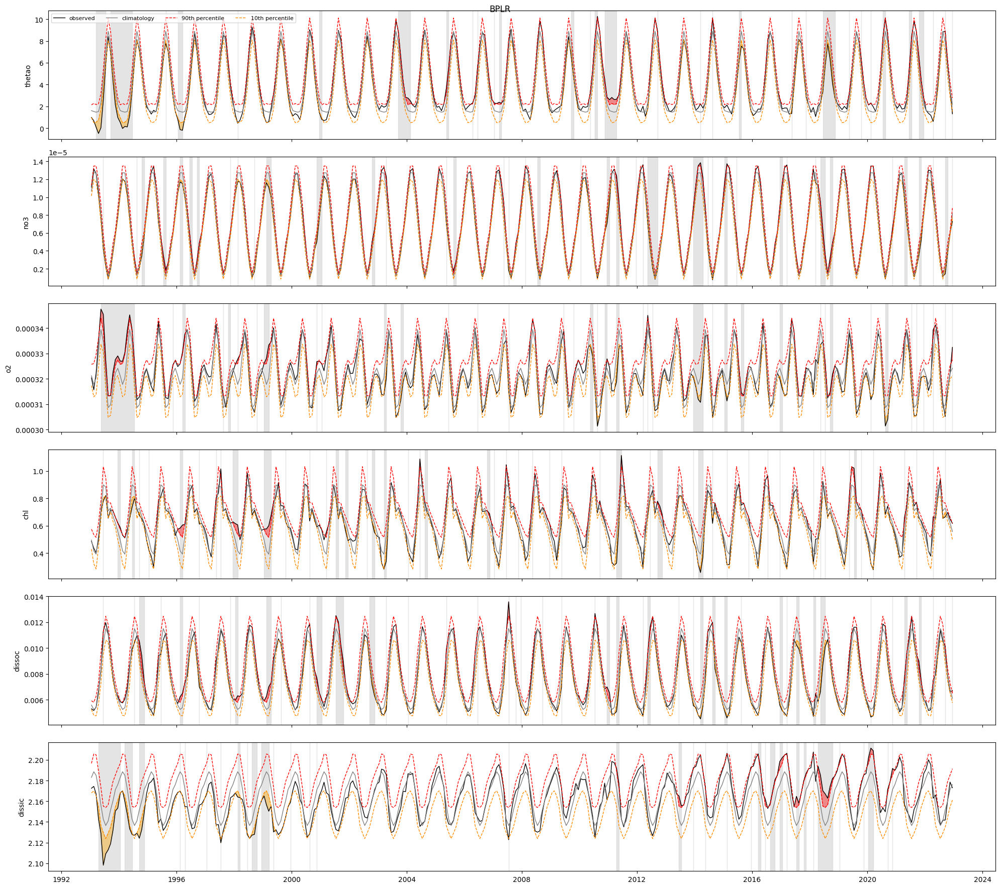

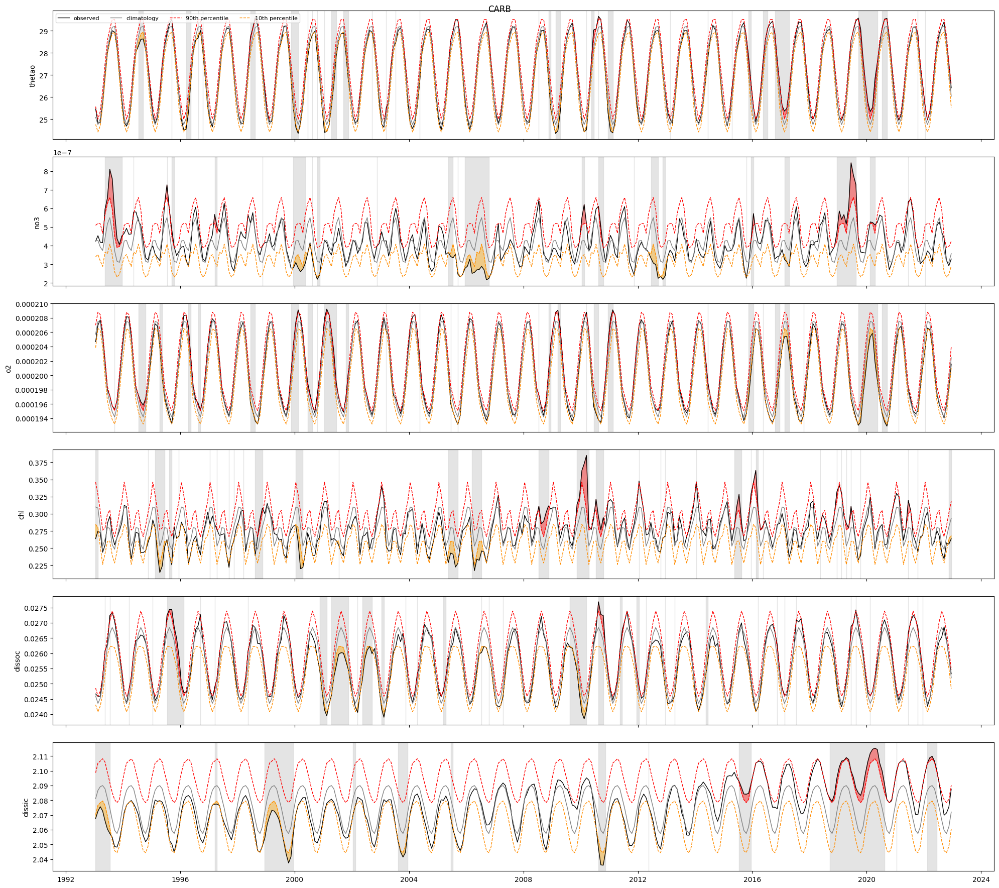

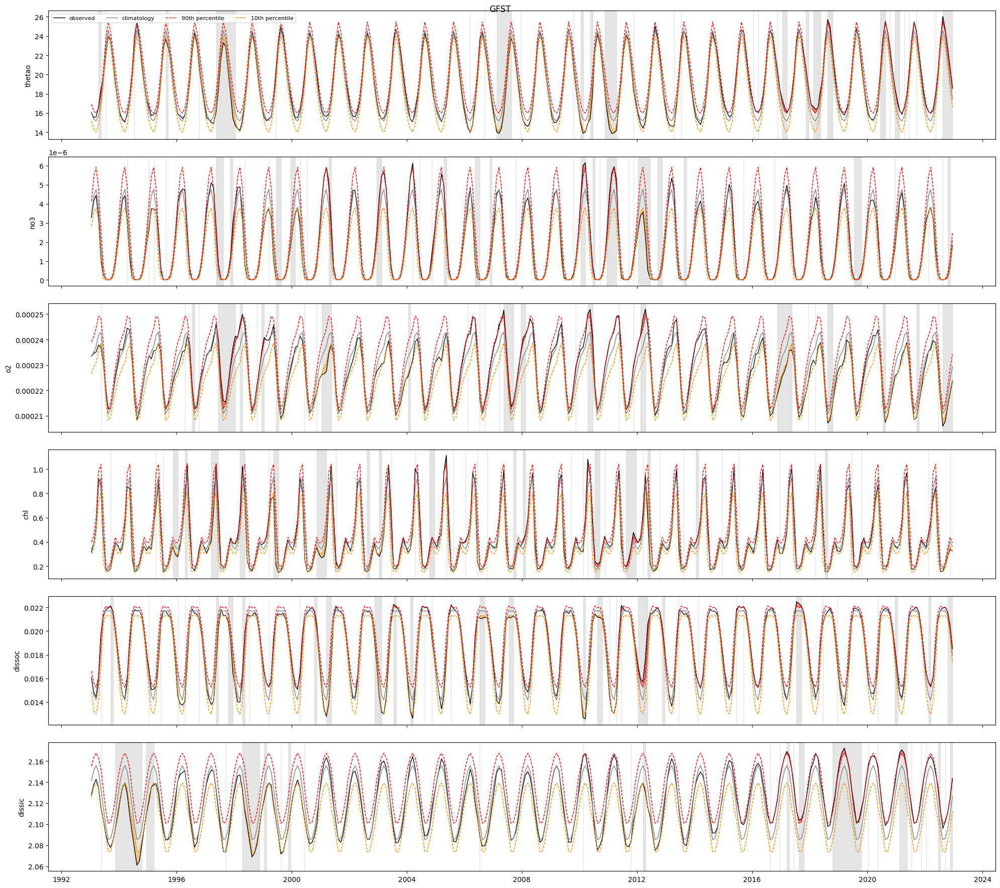

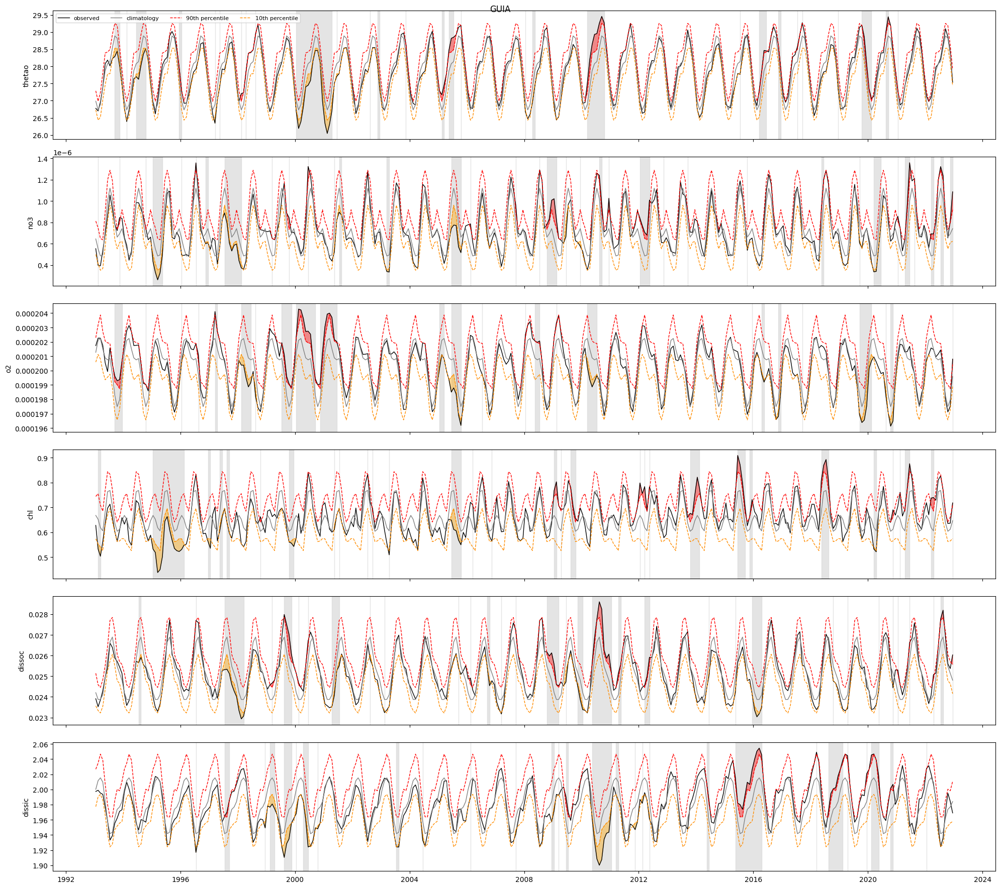

...

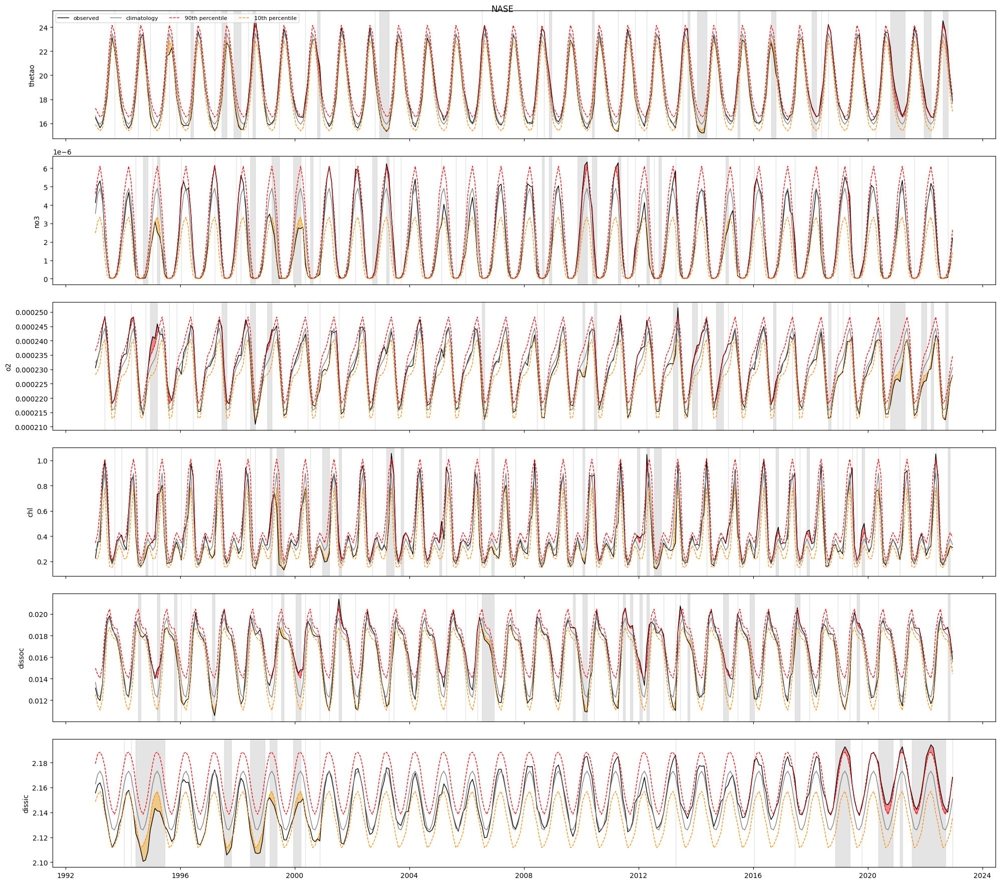

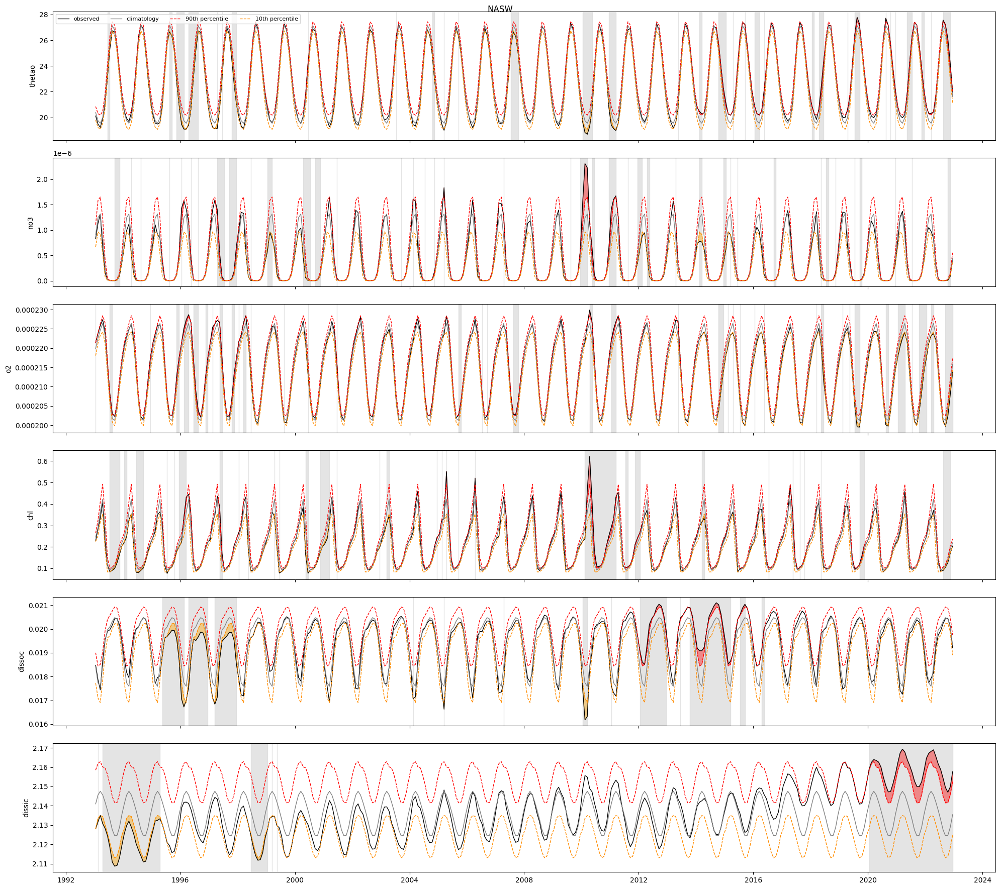

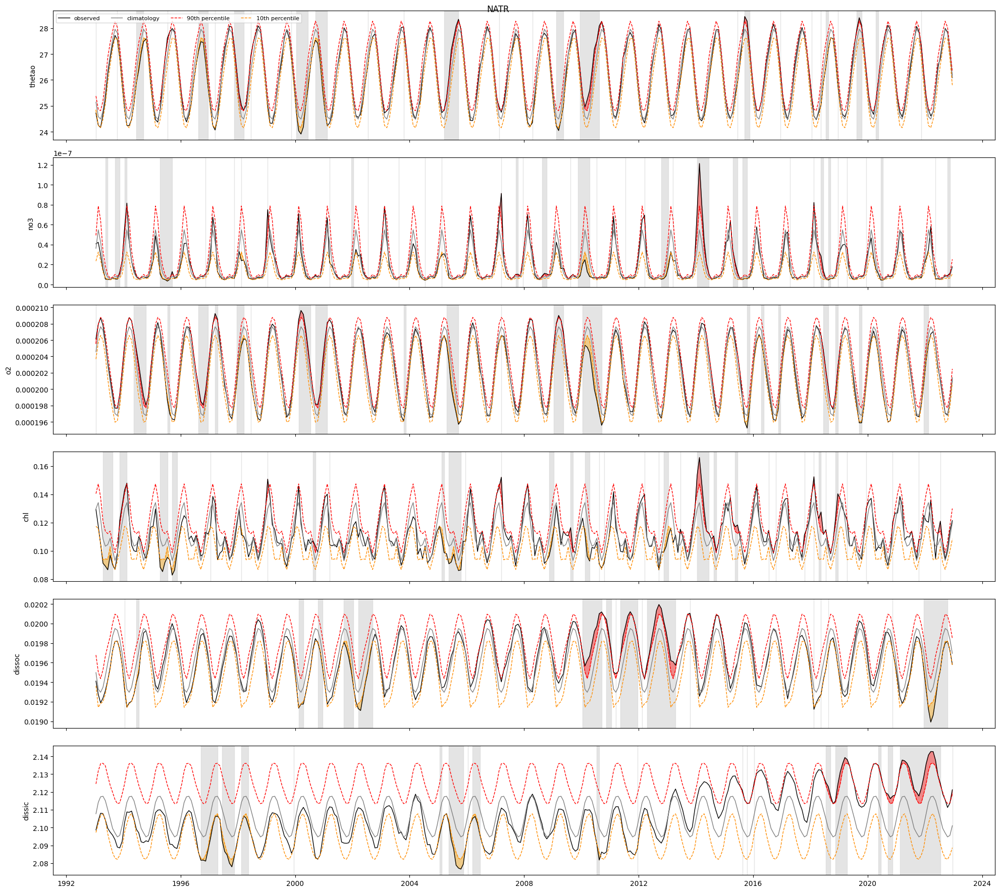

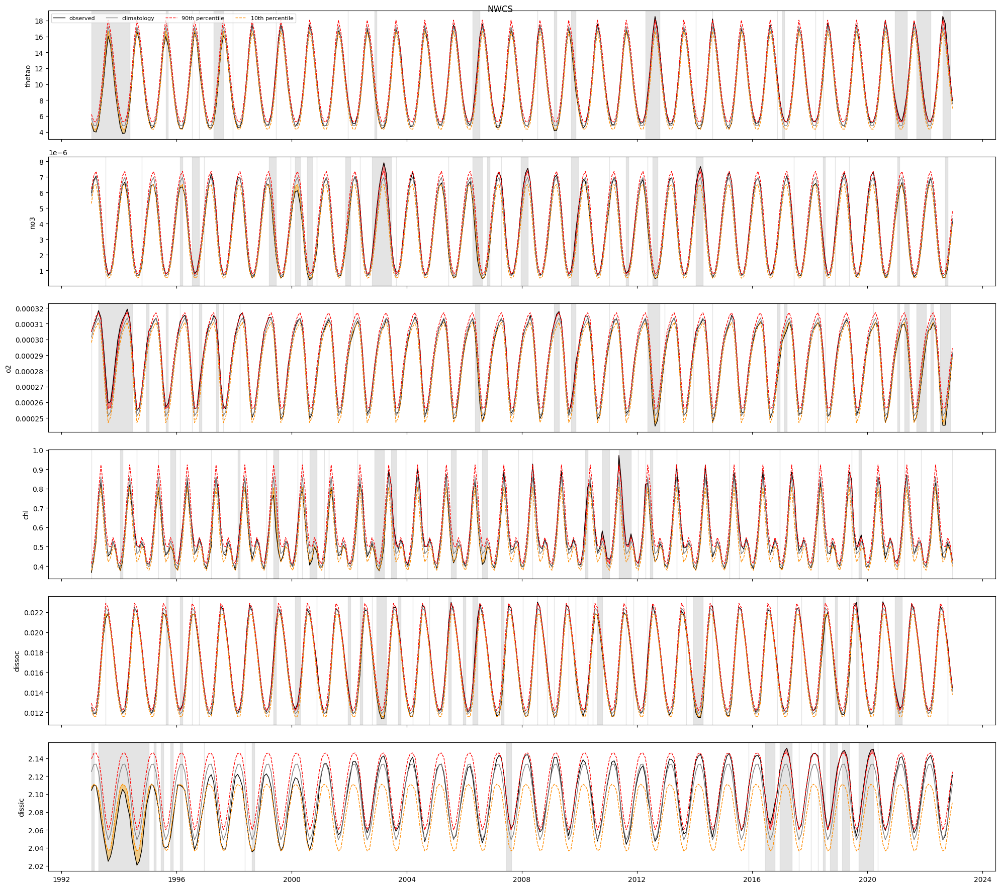

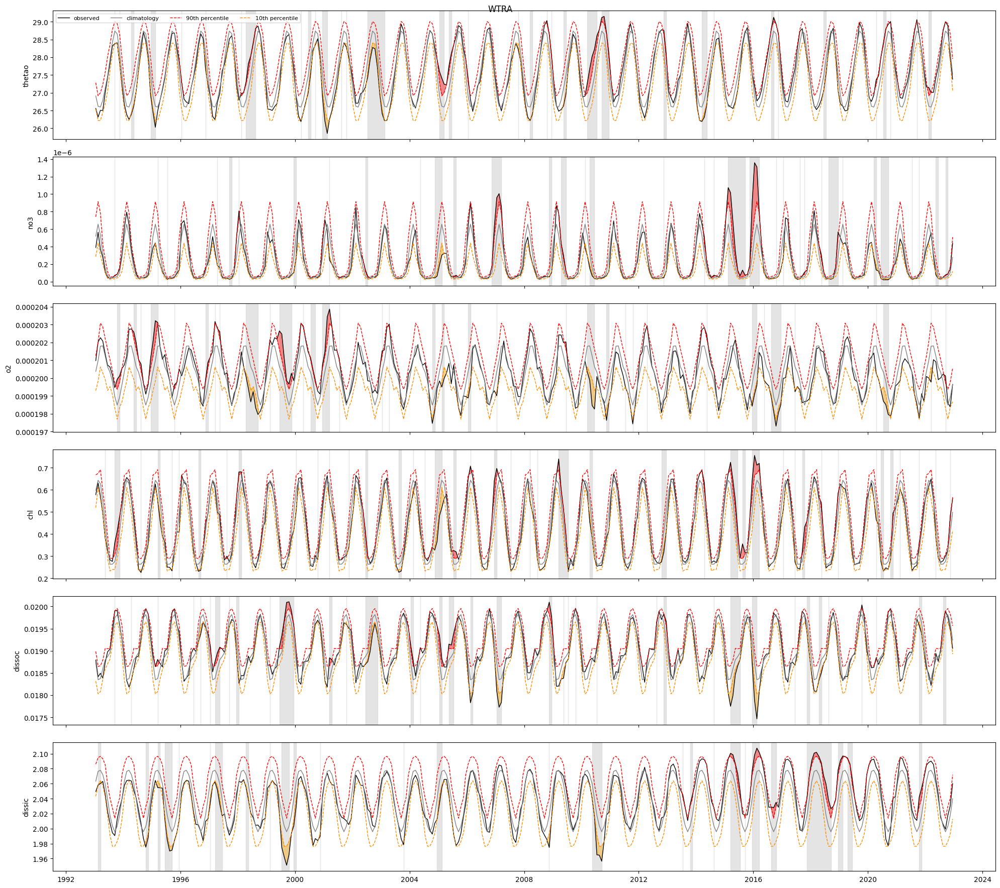

In [42]:
for province in regions:
    plot_province(province)

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))

for ax, var in zip(axs.flat, vars):
    path, surface = vars[var]
    
    tracer_field = xr.open_mfdataset(path)[var].isel(time=-1)
    if surface:
        tracer_field = tracer_field.isel(z_l=0)

    tracer_field.plot(ax=ax, robust=True)
    ax.set_title(f"{var}, {str(tracer_field.time.values)[:7]}")

fig.tight_layout()
plt.show()